In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [19]:
# Load the dataset
df = pd.read_csv("Titanic.csv")
# Display the first five rows
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (891, 12)


In [6]:
# Check data types
print("\nData types:")
print(df.dtypes)


Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [7]:
# Data wrangling
#Check missing values
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [8]:
# Check duplicate records
print("\nDuplicates:", df.duplicated().sum())


Duplicates: 0


In [21]:
# Fill missing Age values with median
df["Age"] = df["Age"].fillna(df["Age"].median())

In [22]:
# Fill missing Embarked values with mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [23]:
# Check missing values again
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64


In [24]:
# Select the important columns
df = df[["Survived", "Pclass", "Sex", "Age", "Fare", "Embarked"]]

In [ ]:
# Convert categorical variables into numerical values
df = pd.get_dummies(df, columns=["Sex", "Embarked"], drop_first=True, dtype=int)

In [25]:
# Select important columns
df = df[["Survived", "Pclass", "Sex", "Age", "Fare", "Embarked"]]

In [26]:
# Encode categorical variables
df = pd.get_dummies(df, columns=["Sex", "Embarked"], drop_first=True, dtype=int)

In [27]:
# Display the first five rows
df.head()

,Survived,Pclass,Age,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,7.2500,1,0,1
1,1,1,38.0,71.2833,0,0,0
2,1,3,26.0,7.9250,0,0,1
3,1,1,35.0,53.1000,0,0,1
4,0,3,35.0,8.0500,1,0,1


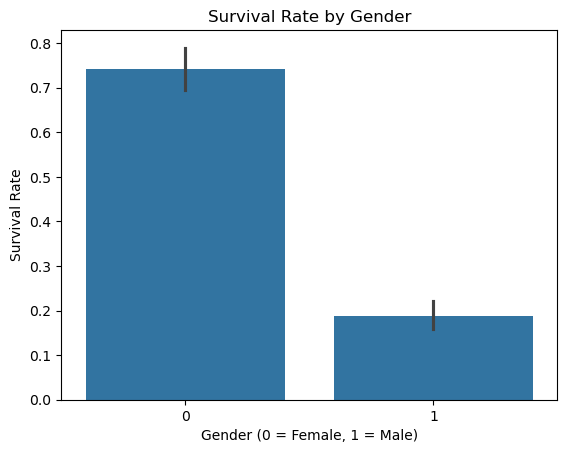

In [28]:
# exploratory data analysis (EDA)
# Survival rate by gender
sns.barplot(x="Sex_male", y="Survived", data=df)
plt.title("Survival Rate by Gender")
plt.xlabel("Gender (0 = Female, 1 = Male)")
plt.ylabel("Survival Rate")
plt.show()

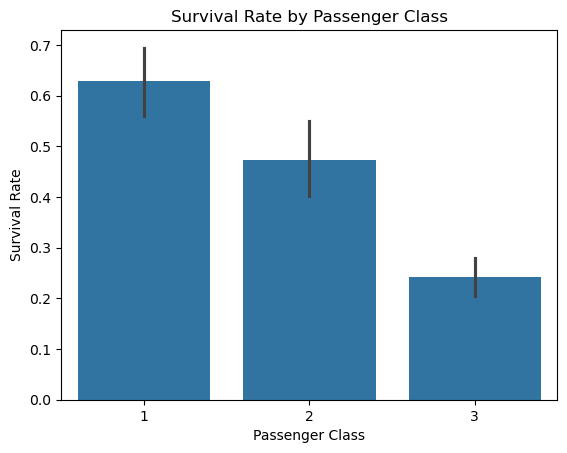

In [29]:
# Survival rate by passenger class
sns.barplot(x="Pclass", y="Survived", data=df)
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

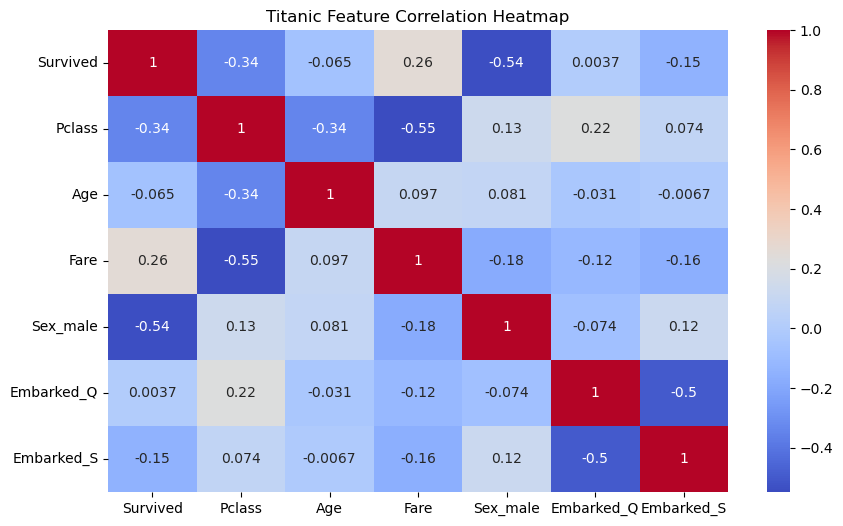

In [30]:
# Correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    df.corr(),
    cmap="coolwarm",
    annot=True
)
plt.title("Titanic Feature Correlation Heatmap")
plt.show()

In [31]:
# Separate features and target variable
X = df.drop("Survived", axis=1)
y = df["Survived"]

In [32]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [33]:
# Check the size of training and testing data
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (712, 6)
Testing data: (179, 6)


In [34]:
# Build Logistic Regression model
log_model = LogisticRegression(max_iter=1000)
# Train the model
log_model.fit(X_train, y_train)
# Make predictions
log_predictions = log_model.predict(X_test)
# Display predictions
print("Logistic Regression Predictions:")
print(log_predictions)

Logistic Regression Predictions:
[0 0 0 1 1 1 1 0 1 1 0 0 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 1 1 1 0 0 0
 1 1 0 0 0 0 0 1 0 0 0 0 0 1 1 0 1 0 1 0 1 1 1 0 1 1 0 0 1 0 0 0 1 1 1 1 1
 0 0 1 1 1 0 0 1 1 0 0 0 1 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 1
 0 1 0 0 0 0 0 1 0 0 1 1 0 0 1 1 1 1 0 1 0 0 1 0 1 1 0 0 1 0 1 0 0 1 1 0 0
 1 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 0 0 0 1 0 0 1 1 0 1 0 0 0 1 1]


In [35]:
# Build Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

In [36]:
# Train the model
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [37]:
# Make predictions
rf_predictions = rf_model.predict(X_test)

In [38]:
# Display predictions
print("Random Forest Predictions:")
print(rf_predictions)

Random Forest Predictions:
[0 0 1 1 0 1 1 0 1 1 1 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 1 1 1 0 0 1
 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 0 1 1 1 1 1
 0 0 1 1 1 0 0 1 1 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 1 0 1
 0 1 1 0 0 1 0 1 0 0 1 1 1 0 0 1 1 0 0 1 0 0 1 1 0 1 0 0 0 0 1 1 0 1 1 0 1
 1 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 0 1 0 1 0 0 1 1 1 0 0 0 0 1 1]


In [40]:
#6. prediction and evaluation
# Calculate Logistic Regression accuracy
log_accuracy = accuracy_score(y_test, log_predictions)

In [41]:
# Calculate Random Forest accuracy
rf_accuracy = accuracy_score(y_test, rf_predictions)

In [42]:
# Display model accuracy
print("Logistic Regression Accuracy:", log_accuracy)
print("Random Forest Accuracy:", rf_accuracy)

Logistic Regression Accuracy: 0.7988826815642458
Random Forest Accuracy: 0.7988826815642458


In [43]:
# Confusion matrix for Logistic Regression
print("Logistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, log_predictions))

Logistic Regression Confusion Matrix:
[[88 17]
 [19 55]]


In [44]:
# Confusion matrix for Random Forest
print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

Random Forest Confusion Matrix:
[[86 19]
 [17 57]]


In [45]:
# Classification report for Logistic Regression
print("Logistic Regression Classification Report:")
print(classification_report(y_test, log_predictions))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.84      0.83       105
           1       0.76      0.74      0.75        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



In [46]:
# Classification report for Random Forest
print("Random Forest Classification Report:")
print(classification_report(y_test, rf_predictions))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.82      0.83       105
           1       0.75      0.77      0.76        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179

